# 2_gridsearch_noise: the 1_gridsearch test with noisy target spectra

Repeats the chi^2 grid search of `1_gridsearch.ipynb` after adding white Gaussian noise to the target spectra (the random-faculae disk and the three random band scenarios). The 27 grid templates stay noiseless.

- Noise: sigma = intensity / SNR in every 0.0087 A bin, SNR = 1000, 300, 100; 200 realisations per target and SNR, fixed seeds.
- Statistic: chi^2 = sum((target - template)^2 / sigma^2) on spectra divided by their own mean over the common bins (sigma divided by the same mean).
- No new simulations: the spectra are loaded from the two caches written by `1_gridsearch.ipynb`, so this notebook only depends on those files.

Run from `actress_highres/actress/` (all paths are relative to it).

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# ----- load the noiseless spectra written by 1_gridsearch.ipynb -----
grid_cache_file = './outputs/gridsearch/1_gridsearch_v4000_res3d5_res2d200_4300.1_4399.9_randomseed0.npz'
band_cache_file = './outputs/gridsearch/1_gridsearch_randombands_v4000_res3d5_res2d200_4300.1_4399.9_seeds1-3.npz'
for cache_file in (grid_cache_file, band_cache_file):
    if not os.path.exists(cache_file):
        raise FileNotFoundError(f"{cache_file} not found; run 1_gridsearch.ipynb first")

grid_cache = np.load(grid_cache_file)
band_cache = np.load(band_cache_file)
# grid config: v_eq, res3d, res2d, n wavelengths, random seed, random r, random inc, n random faculae
print(f"grid cache config {grid_cache['config']}")
print(f"band cache config {band_cache['config']}")

spectra = {}          # name -> (bin centres (A), intensity per bin)
visible_ff = {}
inclination = {}      # deg
for cache in (grid_cache, band_cache):
    for k, name in enumerate(cache['run_names']):
        spectra[name] = (cache[f'bins_{name}'], cache[f'spectrum_{name}'])
        visible_ff[name] = cache['visible_ffs'][k]
for k, name in enumerate(band_cache['run_names']):
    inclination[name] = band_cache['incs'][k]
inclination['random'] = grid_cache['config'][6]

grid_incs = [0, 45, 90]   # deg, as in 1_gridsearch
grid_geometries = ['polar_caps', 'equatorial', 'bands_pm30']
grid_target_ffs = [0.10, 0.20, 0.50]
template_names = [f'{geometry}_ff{target_ff:.2f}_i{inc}'
                  for geometry in grid_geometries for inc in grid_incs for target_ff in grid_target_ffs]
for name in template_names:
    if name not in spectra:
        raise KeyError(f"Grid template {name} missing from {grid_cache_file}")
    inclination[name] = float(name.split('_i')[-1])

target_names = ['random'] + [name for name in band_cache['run_names'] if name.startswith('random_bands')]

# Common bins: those every template and target has after its own edge trimming (set by i = 90).
common_bins = spectra[target_names[0]][0]
for name in template_names + target_names:
    common_bins = np.intersect1d(common_bins, spectra[name][0])
print(f"{len(template_names)} templates, targets {target_names}")
print(f"{len(common_bins)} common bins, {common_bins[0]:.4f}-{common_bins[-1]:.4f} A")


def on_common_bins(name):
    """Intensity of `name` on common_bins (raises if any common bin is missing)."""
    bins, spectrum = spectra[name]
    on_common = np.isin(bins, common_bins)
    if on_common.sum() != len(common_bins):
        raise ValueError(f"{name} does not cover all common bins")
    return spectrum[on_common]


# Templates divided by their own mean, as in 1_gridsearch: (n_templates, n_bins)
template_matrix = np.array([on_common_bins(name) / np.mean(on_common_bins(name)) for name in template_names])

grid cache config [4.0000e+03 5.0000e+00 2.0000e+02 1.1473e+04 0.0000e+00 5.0000e+00
 4.5000e+01 1.1200e+02]
band cache config [4.0000e+03 5.0000e+00 2.0000e+02 1.1473e+04 3.0000e+00 2.0000e+00
 2.0000e+01]
27 templates, targets ['random', 'random_bands_seed1', 'random_bands_seed2', 'random_bands_seed3']
11457 common bins, 4300.1668-4399.8295 A


In [3]:
# ----- noisy targets and weighted chi^2 -----
# Each realisation: observed = true + N(0, sigma), sigma = true / SNR per bin. The observed spectrum
# and sigma are both divided by the observed mean, the normalisation an observer can actually do.
snr_levels = [1000, 300, 100]   # per 0.0087 A bin
n_realisations = 200
noise_seed = 0                  # generator for (target k, SNR j) is default_rng([noise_seed, k, j])
n_bins = len(common_bins)


def weighted_chi2(target_normalised, sigma_normalised):
    """chi^2 of each template against each row: (n_realisations, n_templates)."""
    chi2 = np.zeros((target_normalised.shape[0], len(template_names)))
    for t in range(len(template_names)):
        residual = (target_normalised - template_matrix[t]) / sigma_normalised
        chi2[:, t] = np.sum(residual ** 2, axis=1)
    return chi2


results = {}   # (target, snr) -> dict
for k, target in enumerate(target_names):
    true_spectrum = on_common_bins(target)
    true_normalised = true_spectrum / np.mean(true_spectrum)
    # Noiseless references: the 1_gridsearch statistic, and the weighted one (whose ranking does not
    # depend on SNR, because sigma / mean = true_normalised / SNR only rescales every chi^2 by SNR^2).
    unweighted = np.sum((true_normalised - template_matrix) ** 2, axis=1)
    weighted_noiseless = np.sum(((true_normalised - template_matrix) / true_normalised) ** 2, axis=1)
    for j, snr in enumerate(snr_levels):
        rng = np.random.default_rng([noise_seed, k, j])
        sigma = true_spectrum / snr
        observed = true_spectrum + rng.normal(size=(n_realisations, n_bins)) * sigma
        observed_mean = np.mean(observed, axis=1, keepdims=True)
        chi2 = weighted_chi2(observed / observed_mean, sigma / observed_mean)
        winners = np.argmin(chi2, axis=1)
        results[(target, snr)] = {
            'chi2': chi2,
            'win_fraction': np.bincount(winners, minlength=len(template_names)) / n_realisations,
            'best_reduced_chi2': np.min(chi2, axis=1) / n_bins,   # no fitted parameters: dof = n_bins
            'unweighted_best': template_names[int(np.argmin(unweighted))],
            'weighted_best': template_names[int(np.argmin(weighted_noiseless))],
            'example': observed[0] / observed_mean[0],
            'true_normalised': true_normalised,
        }

# Noise-only floor: chi^2 of the truth itself would be ~ n_bins (reduced ~1); anything well above
# that in the best template is model mismatch, not noise.
print(f"{'target':20s} {'noiseless best (unweighted)':30s} {'noiseless best (weighted)':30s}")
for target in target_names:
    r = results[(target, snr_levels[0])]
    print(f"{target:20s} {r['unweighted_best']:30s} {r['weighted_best']:30s}")

print(f"\nNoisy recovery, {n_realisations} realisations per SNR. 'agree' = fraction won by the noiseless weighted best.")
print(f"{'target':20s} {'SNR':>5s} {'most frequent winner':28s} {'rate':>5s} {'agree':>6s} {'median best chi2_red':>21s}")
for target in target_names:
    for snr in snr_levels:
        r = results[(target, snr)]
        top = int(np.argmax(r['win_fraction']))
        agree = r['win_fraction'][template_names.index(r['weighted_best'])]
        print(f"{target:20s} {snr:5d} {template_names[top]:28s} {r['win_fraction'][top]:5.2f} {agree:6.2f} "
              f"{np.median(r['best_reduced_chi2']):21.3f}")

target               noiseless best (unweighted)    noiseless best (weighted)     
random               bands_pm30_ff0.20_i45          bands_pm30_ff0.20_i45         
random_bands_seed1   polar_caps_ff0.20_i90          polar_caps_ff0.20_i90         
random_bands_seed2   polar_caps_ff0.10_i90          polar_caps_ff0.10_i90         
random_bands_seed3   bands_pm30_ff0.20_i90          bands_pm30_ff0.20_i90         

Noisy recovery, 200 realisations per SNR. 'agree' = fraction won by the noiseless weighted best.
target                 SNR most frequent winner          rate  agree  median best chi2_red
random                1000 bands_pm30_ff0.20_i45         1.00   1.00                 1.886
random                 300 bands_pm30_ff0.20_i45         1.00   1.00                 1.077
random                 100 bands_pm30_ff0.20_i45         0.89   0.89                 1.010
random_bands_seed1    1000 polar_caps_ff0.20_i90         1.00   1.00               188.929
random_bands_seed1     300 polar

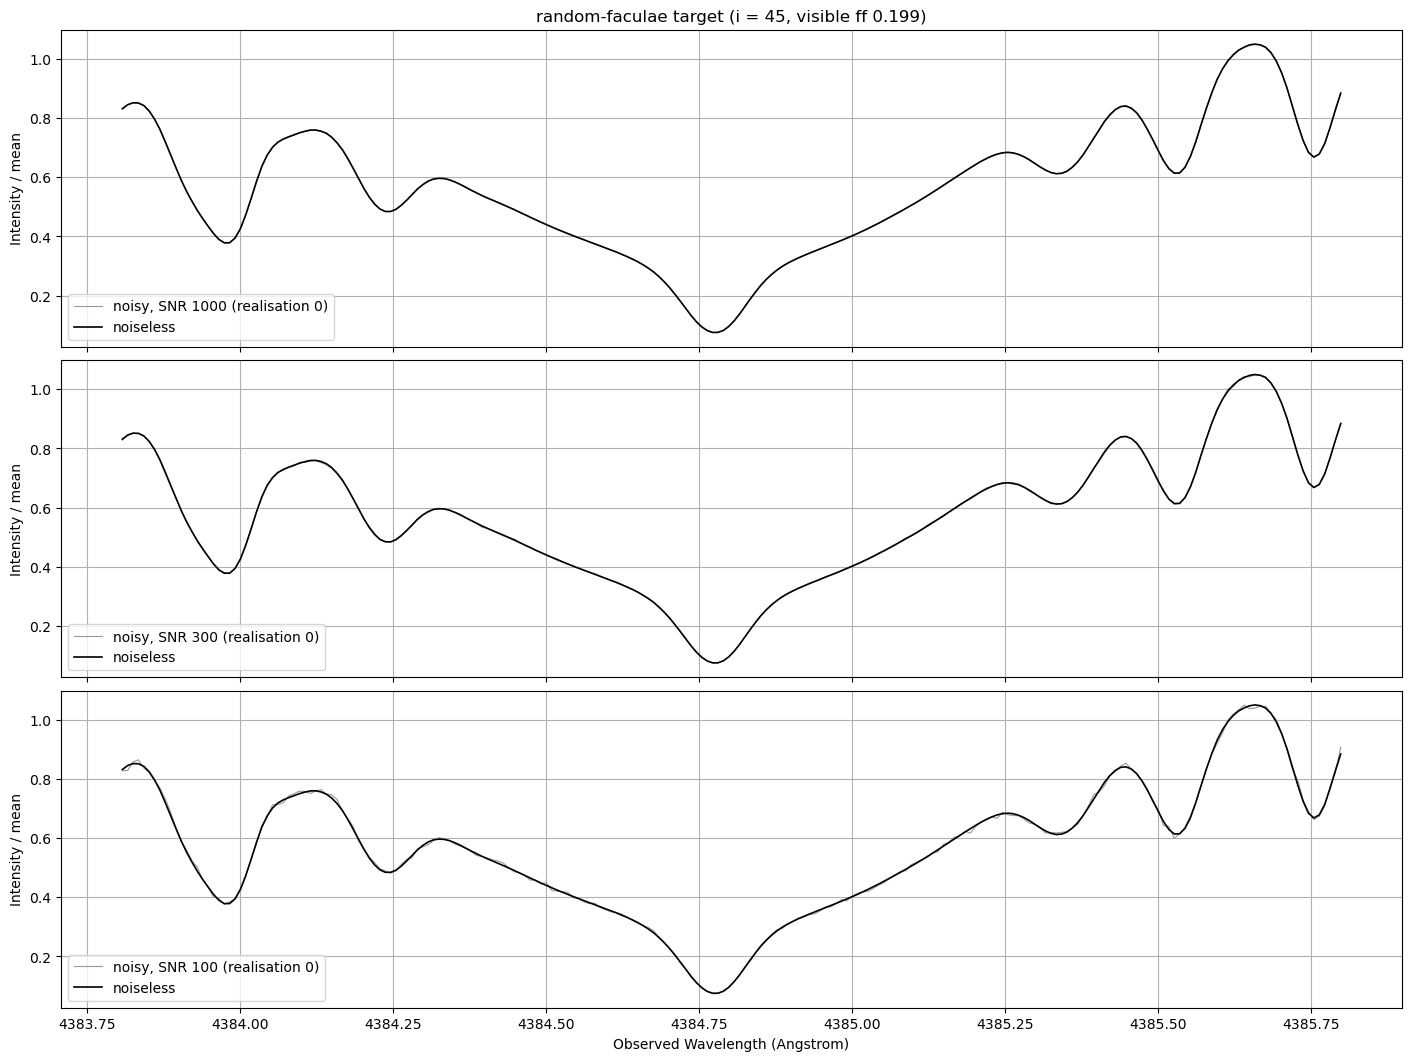

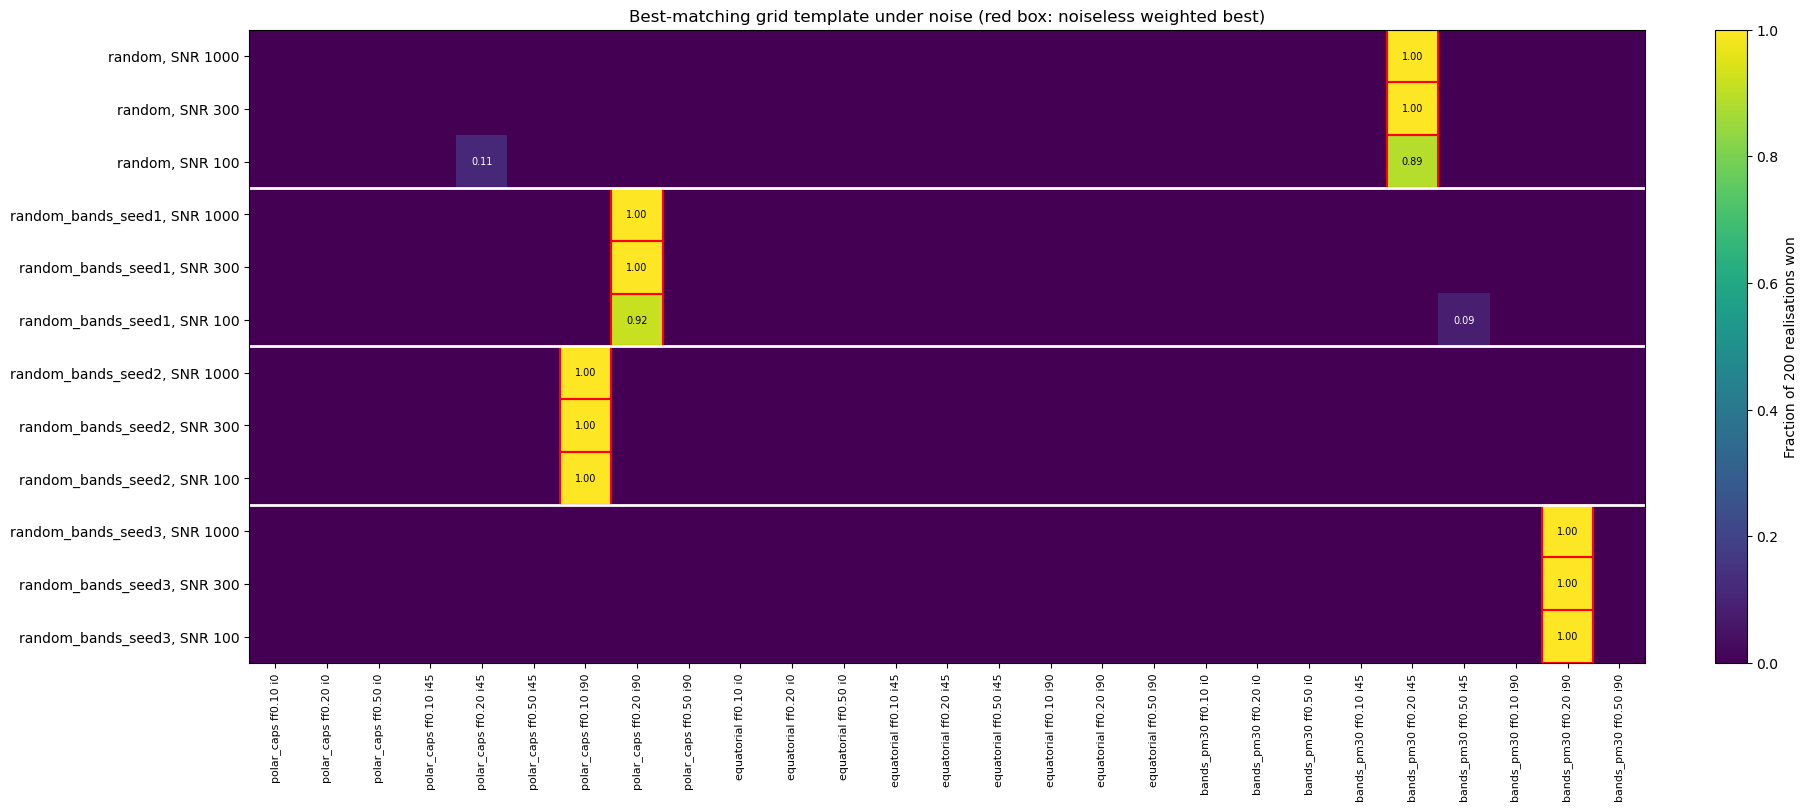

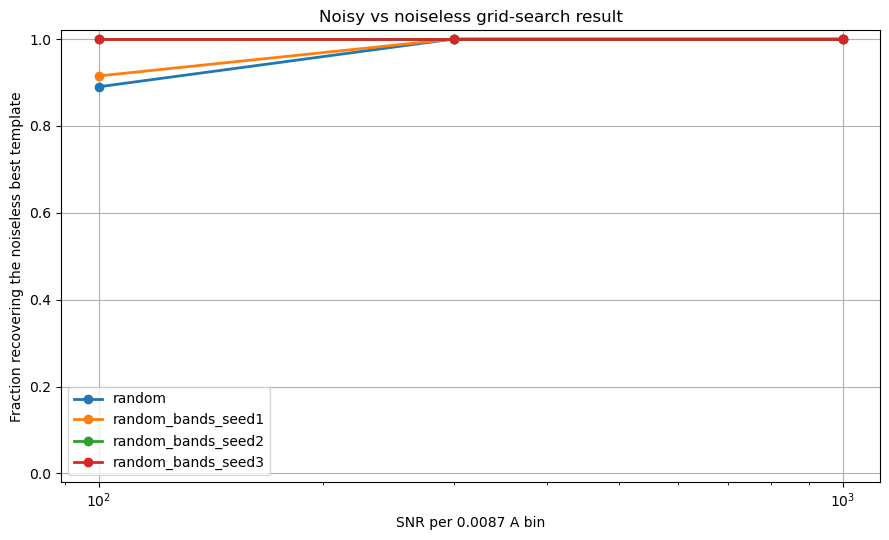

In [4]:
# ----- what the noise looks like: 2 A around 4384.76 A (the image wavelength in 1_gridsearch) -----
zoom = (common_bins >= 4383.8) & (common_bins <= 4385.8)
fig, axes = plt.subplots(len(snr_levels), 1, figsize=(14, 3.5 * len(snr_levels)), sharex=True, constrained_layout=True)
for ax, snr in zip(axes, snr_levels):
    r = results[('random', snr)]
    ax.plot(common_bins[zoom], r['example'][zoom], linewidth=0.8, color='0.6', label=f'noisy, SNR {snr} (realisation 0)')
    ax.plot(common_bins[zoom], r['true_normalised'][zoom], linewidth=1.2, color='k', label='noiseless')
    ax.set_ylabel('Intensity / mean')
    ax.legend(loc='lower left')
    ax.grid(True)
axes[0].set_title('random-faculae target (i = 45, visible ff 0.199)')
axes[-1].set_xlabel('Observed Wavelength (Angstrom)')
plt.show()

# ----- win fraction of every template, per target and SNR -----
row_labels = []
win_matrix = []
for target in target_names:
    for snr in snr_levels:
        row_labels.append(f'{target}, SNR {snr}')
        win_matrix.append(results[(target, snr)]['win_fraction'])
win_matrix = np.array(win_matrix)

fig, ax = plt.subplots(figsize=(18, 8), constrained_layout=True)
im = ax.imshow(win_matrix, cmap='viridis', vmin=0, vmax=1, aspect='auto')
for row in range(win_matrix.shape[0]):
    for column in range(win_matrix.shape[1]):
        if win_matrix[row, column] > 0:
            ax.text(column, row, f'{win_matrix[row, column]:.2f}', ha='center', va='center', fontsize=7,
                    color='k' if win_matrix[row, column] > 0.5 else 'w')
        # Outline the noiseless weighted best for that target, so disagreement is visible.
        target = target_names[row // len(snr_levels)]
        if template_names[column] == results[(target, snr_levels[0])]['weighted_best']:
            ax.add_patch(plt.Rectangle((column - 0.5, row - 0.5), 1, 1, fill=False, edgecolor='r', linewidth=1.5))
ax.set_xticks(range(len(template_names)))
ax.set_xticklabels([name.replace('_ff', ' ff').replace('_i', ' i') for name in template_names], fontsize=8, rotation=90)
ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels)
for boundary in range(len(snr_levels), len(row_labels), len(snr_levels)):
    ax.axhline(boundary - 0.5, color='w', linewidth=2)
fig.colorbar(im, ax=ax, label=f'Fraction of {n_realisations} realisations won')
ax.set_title('Best-matching grid template under noise (red box: noiseless weighted best)')
plt.show()

# ----- recovery of the noiseless answer vs SNR -----
fig, ax = plt.subplots(figsize=(9, 5.5))
for target in target_names:
    agree = [results[(target, snr)]['win_fraction'][template_names.index(results[(target, snr)]['weighted_best'])]
             for snr in snr_levels]
    ax.plot(snr_levels, agree, marker='o', linewidth=2, label=target)
ax.set_xscale('log')
ax.set_xlabel('SNR per 0.0087 A bin')
ax.set_ylabel('Fraction recovering the noiseless best template')
ax.set_ylim(-0.02, 1.02)
ax.set_title('Noisy vs noiseless grid-search result')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

200 realisations per SNR; SNR is per 0.0087 A bin. Reported: the first (highest) SNR where recovery drops below the level.
target               noiseless best             exact < 0.9 exact < 0.5  inc < 0.5  ff < 0.5  exact at SNR 0.1
random               bands_pm30_ff0.20_i45            74.99          10       0.24      1.33             0.005
random_bands_seed1   polar_caps_ff0.20_i90              100       23.71       1.78     23.71             0.010
random_bands_seed2   polar_caps_ff0.10_i90             5.62        1.33      never      0.56             0.105
random_bands_seed3   bands_pm30_ff0.20_i90               10        4.22      never      1.78             0.000


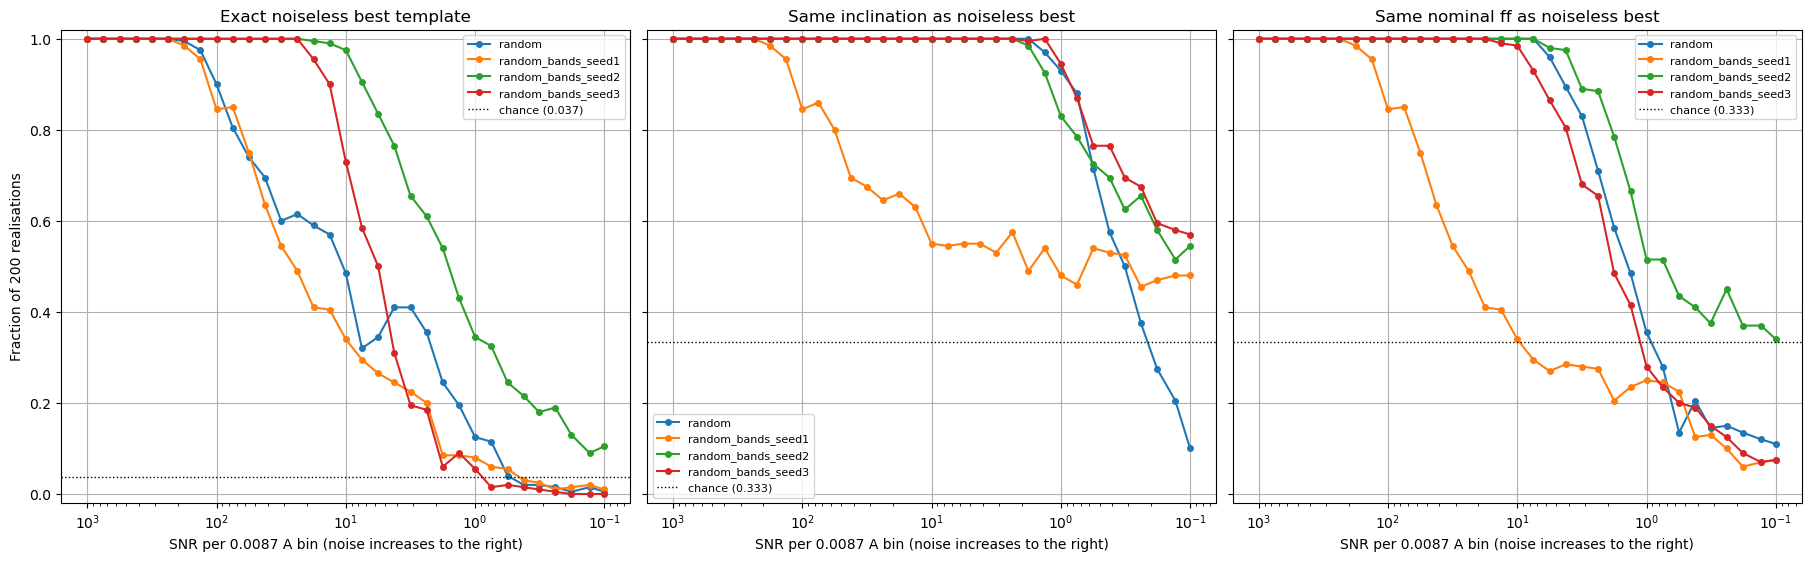

In [5]:
# ----- noise breakdown: lower the SNR until the noiseless best fit is no longer found -----
# Same noise model, normalisation and weighted chi^2 as above, on a log grid of SNR from 1000 down
# to 0.1 (below SNR ~3 many bins go negative, but chi^2 is still well defined). 'Recovered' = the noisy search picks the noiseless weighted best template. Partial recovery
# is tracked too: the winner has the right inclination, or the right nominal ff, whatever its geometry.
# Chance level for a blind pick among the 27 templates is 1/27 = 0.037.
sweep_snrs = np.round(np.logspace(3, -1, 33), 2)   # 1000 -> 0.1 per 0.0087 A bin
sweep_realisations = 200
sweep_seed = 1                                     # generator per (target k, SNR j): default_rng([sweep_seed, k, j])
chance_level = 1 / len(template_names)

template_incs = np.array([inclination[name] for name in template_names])
template_nominal_ffs = np.array([float(name.split('_ff')[1].split('_i')[0]) for name in template_names])

sweep = {}   # target -> dict of arrays over sweep_snrs
for k, target in enumerate(target_names):
    true_spectrum = on_common_bins(target)
    reference = template_names.index(results[(target, snr_levels[0])]['weighted_best'])
    exact, right_inc, right_ff = [], [], []
    for j, snr in enumerate(sweep_snrs):
        rng = np.random.default_rng([sweep_seed, k, j])
        sigma = true_spectrum / snr
        observed = true_spectrum + rng.normal(size=(sweep_realisations, n_bins)) * sigma
        observed_mean = np.mean(observed, axis=1, keepdims=True)
        winners = np.argmin(weighted_chi2(observed / observed_mean, sigma / observed_mean), axis=1)
        exact.append(np.mean(winners == reference))
        right_inc.append(np.mean(template_incs[winners] == template_incs[reference]))
        right_ff.append(np.mean(template_nominal_ffs[winners] == template_nominal_ffs[reference]))
    sweep[target] = {'reference': template_names[reference], 'exact': np.array(exact),
                     'inc': np.array(right_inc), 'ff': np.array(right_ff)}


def breakdown_snr(recovery, level):
    """Highest swept SNR at which recovery is below `level` (sweep runs from high to low SNR); None if never."""
    below = np.where(recovery < level)[0]
    return None if len(below) == 0 else sweep_snrs[below[0]]


print(f"{sweep_realisations} realisations per SNR; SNR is per 0.0087 A bin. Reported: the first (highest) SNR where "
      f"recovery drops below the level.")
print(f"{'target':20s} {'noiseless best':26s} {'exact < 0.9':>11s} {'exact < 0.5':>11s} "
      f"{'inc < 0.5':>10s} {'ff < 0.5':>9s} {'exact at SNR 0.1':>17s}")
for target in target_names:
    s = sweep[target]
    columns = [breakdown_snr(s['exact'], 0.9), breakdown_snr(s['exact'], 0.5),
               breakdown_snr(s['inc'], 0.5), breakdown_snr(s['ff'], 0.5)]
    text = ['never' if value is None else f'{value:g}' for value in columns]
    print(f"{target:20s} {s['reference']:26s} {text[0]:>11s} {text[1]:>11s} {text[2]:>10s} {text[3]:>9s} "
          f"{s['exact'][-1]:17.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True, constrained_layout=True)
for ax, key, title in zip(axes, ['exact', 'inc', 'ff'],
                          ['Exact noiseless best template', 'Same inclination as noiseless best', 'Same nominal ff as noiseless best']):
    for target in target_names:
        ax.plot(sweep_snrs, sweep[target][key], marker='o', markersize=4, linewidth=1.5, label=target)
    # Blind-pick level: 1/27 for the exact template, 1/3 for inclination or ff (3 grid values each).
    level = chance_level if key == 'exact' else 1 / 3
    ax.axhline(level, color='k', linestyle=':', linewidth=1, label=f'chance ({level:.3f})')
    ax.legend(fontsize=8)
    ax.set_xscale('log')
    ax.invert_xaxis()   # noise increases to the right
    ax.set_xlabel('SNR per 0.0087 A bin (noise increases to the right)')
    ax.set_title(title)
    ax.grid(True)
axes[0].set_ylabel(f'Fraction of {sweep_realisations} realisations')
axes[0].set_ylim(-0.02, 1.02)
plt.show()
